In [1]:
from pathlib import Path
input_dir = Path.cwd()
input = input_dir/"input"
output = input_dir/"output"
output.mkdir(exist_ok=True)

area_shp = input/"egy_rb_new_2014.shp"

"if there are shp factors"
factors_shp = [(input/"lithology.shp", input/"Lithology.tif")]
column_name = "code"

"factor settings"
factors =[(input/"Landuse.tif", "Landuse", "mode", None, output/"Landuse.tif"), (input/"output_hh.tif", "Dem", "bilinear", None, output/"Dem.tif"), (input/"pmean_an.nc", "Precipitation","bilinear", None, output/"Precipitation.tif"), (input/"tmean_an.nc", "Temperature", "bilinear", None, output/"Temperature.tif"), (input/"slope_4326.tif", "Slope", "bilinear", None, output/"Slope.tif"), (input/"aspect_4326.tif", "Aspect", "bilinear", None, output/"Aspect.tif"), (input/"distance_river_4326.tif", "Distance_to_river", "bilinear", None, output/"Distance_to_river.tif"), (input/"twi_4326.tif", "TWI", "bilinear", None, output/"TWI.tif"), (input/"tpi_4326.tif", "TPI", "bilinear", None, output/"TPI.tif"), (input/"spi_4326.tif", "SPI", "bilinear", None, output/"SPI.tif"), (input/"sti_4326.tif", "STI", "bilinear", None, output/"STI.tif"), (input/"lithology.tif", "Lithology", "mode", "nearest", output/"Lithology.tif")]
reference_grid_tif = input/"Landuse.tif"

"disaster and no disaster points settings"
disaster_shp = input/"floods.shp"
disaster_name = "floods"
crs_code_meters = "EPSG:2100"
use_dbscan = True
buffer_number = 1000
number_merge = 3000
random_state = 1
distance_min = 1000

"if is necessary encoding"
columns_encoding = ["Landuse", "Lithology"]

"model settings"
model_library = "sklearn.ensemble"
model_type = "RandomForestClassifier"
range_parametres =  {"n_estimators" : list(range(100,300)), "max_depth" : list(range(5,20)), "min_samples_split" : list(range(2,10)), "min_samples_leaf" : list(range(1,10)), "random_state" : [1]}
scaling = False


"classify map settings"
method = "Natural_Breaks"
number_classes = 5
classes_boundaries = []


In [2]:
from functions.geospatial_operation.shp_to_tif import shp_to_tif
shp_to_tif(factors_shp, reference_grid_tif, column_name)

<xarray.DataArray (band: 1, y: 8469, x: 11084)> Size: 375MB
array([[[   11.,    11.,    11., ..., -9999., -9999., -9999.],
        [   11.,    11.,    11., ..., -9999., -9999., -9999.],
        [   11.,    11.,    11., ..., -9999., -9999., -9999.],
        ...,
        [-9999., -9999., -9999., ..., -9999., -9999., -9999.],
        [-9999., -9999., -9999., ..., -9999., -9999., -9999.],
        [-9999., -9999., -9999., ..., -9999., -9999., -9999.]]],
      shape=(1, 8469, 11084), dtype=float32)
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 68kB 44.07 44.07 44.07 44.07 ... 35.5 35.5 35.5
  * x            (x) float64 89kB 18.13 18.13 18.13 18.13 ... 29.35 29.35 29.35
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    _FillValue:     -9999.0
    scale_factor:   1.0
    add_offset:     0.0

In [3]:
from functions.geospatial_operation.prepare_factors import prepare_factors
from functions.preprocessing.table_factors import table_factors
from functions.preprocessing.disaster_nodisaster_points import disaster_nodisaster_points
from functions.preprocessing.train_test import training_test

onetif = prepare_factors(area_shp, factors, output, reference_grid_tif, output/"tif_final.tif")
factors, factors_only, factors_coords = table_factors(onetif, output/"factors.csv", output/"factors_only.csv")
dataset = disaster_nodisaster_points(disaster_shp, output/"factors.csv", disaster_name, crs_code_meters, output, use_dbscan, buffer_number, number_merge, random_state, distance_min)
x_train, y_train, x_test, y_test = training_test(dataset, disaster_name, output/"training.csv", output/"test.csv")

In [4]:
from functions.preprocessing.encoding import encoding

x_train_en, x_test_en = encoding(x_train, x_test, columns_encoding, output/"x_train_encoding.csv", output/"x_test_encoding.csv")
x_train_en, factors_en = encoding(x_train, factors_only, columns_encoding, output/"x_train_encoding.csv", output/"factors_encoding.csv")
x_train = x_train_en
x_test =  x_test_en
factors = factors_en

c:\Users\User\Desktop\susceptibility\functions\modeling\model.py:29: ExperimentalWarning: OptunaSearchCV is experimental (supported from v0.17.0). The interface can change in the future.
  optimization = OptunaSearchCV(estimator = model, param_distributions = yperparametres, n_trials = 50 , cv = validation, random_state = random_state, scoring = "roc_auc")
[I 2026-09-01 18:13:09,780] A new study created in memory with name: no-name-2c80472a-82fa-4ca8-acb3-5aa647a065fb
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\optuna\terminator\erroreval.py:113: FutureWarning: `optuna.terminator` module has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.9.0.
  optuna_warn(_DEPRECATION_WARNING_MESSAGE, FutureWarning)
[I 2026-09-01 18:13:18,195] Trial 0 finished with value: 0.986703276647283 and parameters: {'n_estimators': 278, 'max_depth': 7, 'min_samples_split': 3, 'min_samples_leaf': 6, 'random_state

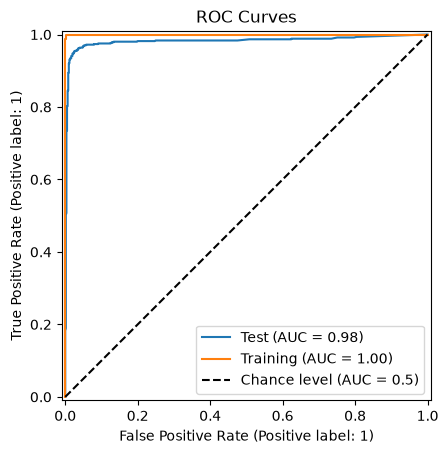

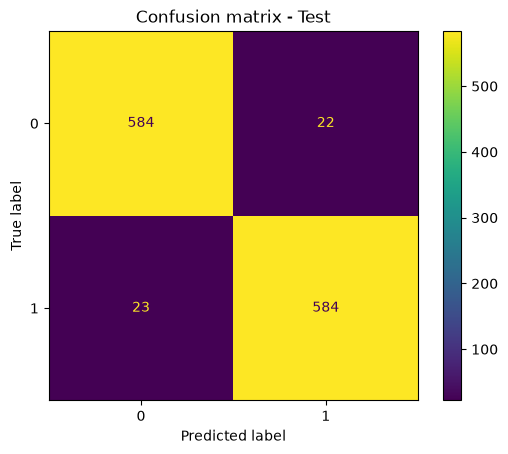

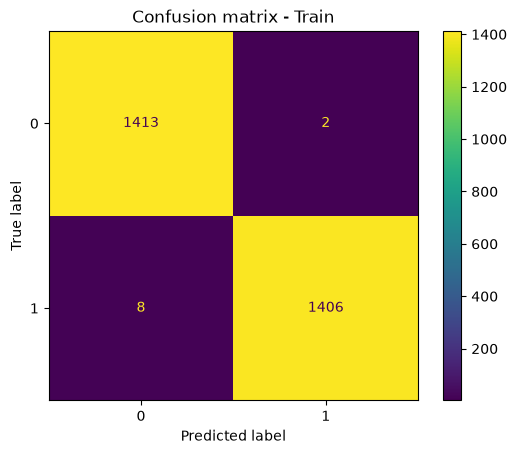

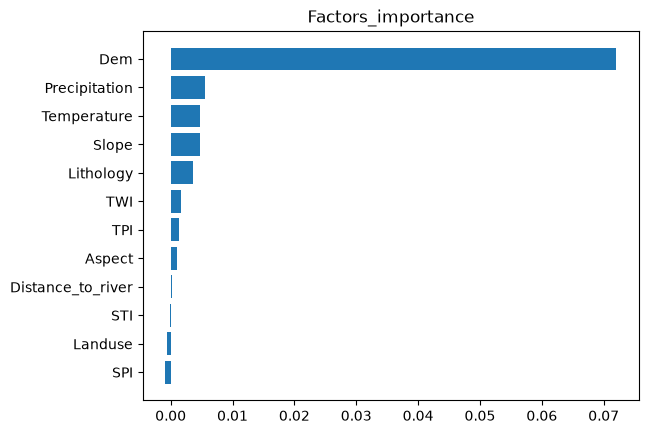

Background dataset has 2829 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=2829 when initializing the masker.
PermutationExplainer explainer: 1214it [12:55,  1.56it/s]                          


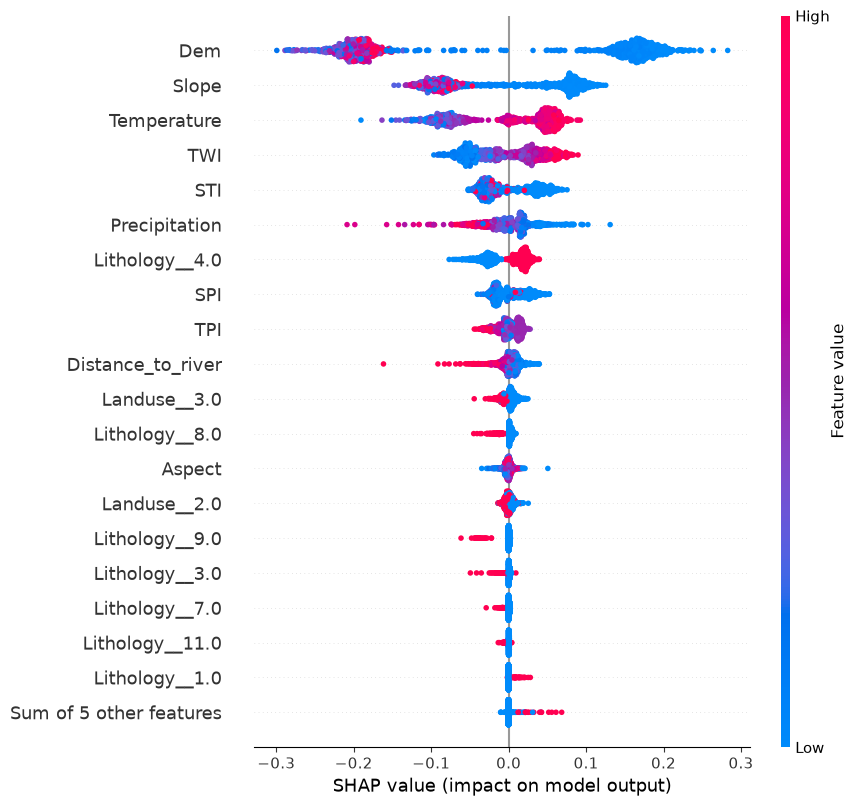

<Figure size 640x480 with 0 Axes>

In [5]:
from functions.modeling.model import model
from functions.modeling.evaluation_model import evaluation_model
from functions.modeling.explain_model import explain_model
from functions.mapping.susceptibility_map import susceptibility_map

model = model(x_train, y_train, model_library, model_type, random_state, scaling, range_parametres, output/"model_resuls.csv", output/"model.joblib")
evaluation_model(x_train, y_train, x_test, y_test, output/"model.joblib", output/"metrics.csv", output/"roc_curves.png", output/"cm_test.png", output/"cm_train.png")
explain_model(x_test, y_test, output/"model.joblib", random_state, output/"factors_importance.png", x_train, output/"SHAP_explanation.png")
susceptibility_map(output/"model.joblib", factors, factors_coords, disaster_name, output/"susceptibility_map.tif", method, number_classes, classes_boundaries, output/"susceptibility_map_classified.tif")